Para esta actividad cargare el archivo breast_cancer.csv, basado en un conjunto de datos sobre características de tumores mamarios, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar si un tumor es maligno (M) o benigno (B) a partir de medidas extraídas de imágenes de biopsias. Las variables incluidas describen propiedades morfológicas y de textura del tumor y se presentan en tres tipos de medida para cada característica:

* `_mean`: valor promedio de la característica en el tumor
* `_se`: error estándar de la característica (variabilidad de la medición)
* `_worst`: peor valor observado de la característica en el tumor

Los indicadores incluidos son:
* `radius_mean` / `radius_se` / `radius_worst`:	Radio del tumor
* `texture_mean` / `texture_se` / `texture_worst`:	Textura del tumor (desviación estándar de intensidad)
* `perimeter_mean` / `perimeter_se` / `perimeter_worst`:	Perímetro del tumor
* `area_mean` / `area_se` / `area_worst`:	Área del tumor
* `smoothness_mean` / `smoothness_se` / `smoothness_worst`:	Suavidad (irregularidad del borde)
* `compactness_mean` / `compactness_se` / `compactness_worst`:	Compacidad (perimeter^2 / area - 1)
* `concavity_mean` / `concavity_se` / `concavity_worst`:	Concavidad de los contornos
* `concave points_mean` / `concave points_se` / `concave points_worst`:	Número de puntos cóncavos en el contorno
* `symmetry_mean` / `symmetry_se` / `symmetry_worst`:	Simetría del tumor
* `fractal_dimension_mean` / `fractal_dimension_se` / `fractal_dimension_worst`:	Dimensión fractal del contorno (complejidad)
* `diagnosis`: Indica si el tumor es benigno (B) o maligno (M). Es la variable de salida o *target*

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.dummy import DummyClassifier
import mlflow
from mlflow.models import infer_signature

In [2]:
cancer_df = pd.read_csv('breast_cancer.csv')
cancer_df.set_index('id', inplace=True)
cancer_df.info()

<class 'pandas.DataFrame'>
Index: 569 entries, 842302 to 92751
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    str    
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  569 non-nu

Tenemos 30 variables numericas y 1 de texto

In [3]:
missing_percent = cancer_df.isna().mean() * 100
missing_percent.sort_values(ascending=False)

diagnosis                  0.0
compactness_se             0.0
symmetry_worst             0.0
concave points_worst       0.0
concavity_worst            0.0
compactness_worst          0.0
smoothness_worst           0.0
area_worst                 0.0
perimeter_worst            0.0
texture_worst              0.0
radius_worst               0.0
fractal_dimension_se       0.0
symmetry_se                0.0
concave points_se          0.0
concavity_se               0.0
smoothness_se              0.0
radius_mean                0.0
area_se                    0.0
perimeter_se               0.0
texture_se                 0.0
radius_se                  0.0
fractal_dimension_mean     0.0
symmetry_mean              0.0
concave points_mean        0.0
concavity_mean             0.0
compactness_mean           0.0
smoothness_mean            0.0
area_mean                  0.0
perimeter_mean             0.0
texture_mean               0.0
fractal_dimension_worst    0.0
dtype: float64

In [4]:
cancer_df.duplicated().sum()

np.int64(0)

No tenemos valores faltantes o duplicados

Se obtienen las estadísticas descriptivas, separando las variables numéricas (con asimetría y curtosis) y las categóricas.

In [5]:
num_df = cancer_df.select_dtypes(include=['float64'])
num_df.select_dtypes(include=['number']).agg([
    'count', 'mean', 'std', 'min',
    lambda x: x.quantile(0.25),
    'median',
    lambda x: x.quantile(0.75), 'max',
    'skew', 'kurt'
])

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
<lambda>,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
median,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
<lambda>,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500
skew,0.942380,0.650450,0.990650,1.645732,0.456324,1.190123,1.401180,1.171180,0.725609,1.304489,...,1.103115,0.498321,1.128164,1.859373,0.415426,1.473555,1.150237,0.492616,1.433928,1.662579
kurt,0.845522,0.758319,0.972214,3.652303,0.855975,1.650130,1.998638,1.066556,1.287933,3.005892,...,0.944090,0.224302,1.070150,4.396395,0.517825,3.039288,1.615253,-0.535535,4.444560,5.244611


In [6]:
cat_df = cancer_df.select_dtypes(include=['object'])
cat_df.describe()

/var/folders/56/fjm7_ygx0933sxy82cbvkync0000gn/T/ipykernel_46591/2845118255.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_df = cancer_df.select_dtypes(include=['object'])


,diagnosis
count,569
unique,2
top,B
freq,357


Voy a crear histogramas apilados de las variables morfológicas (smoothness_mean, compactness_mean, concavity_mean, concave points_mean, symmetry_mean, fractal_dimension_mean) coloreando por diagnosis para explorar la distribución de cada variable según el tipo de tumor. Asi podremos observar si alguna variable pudiera ser un buen discriminador entre las clases


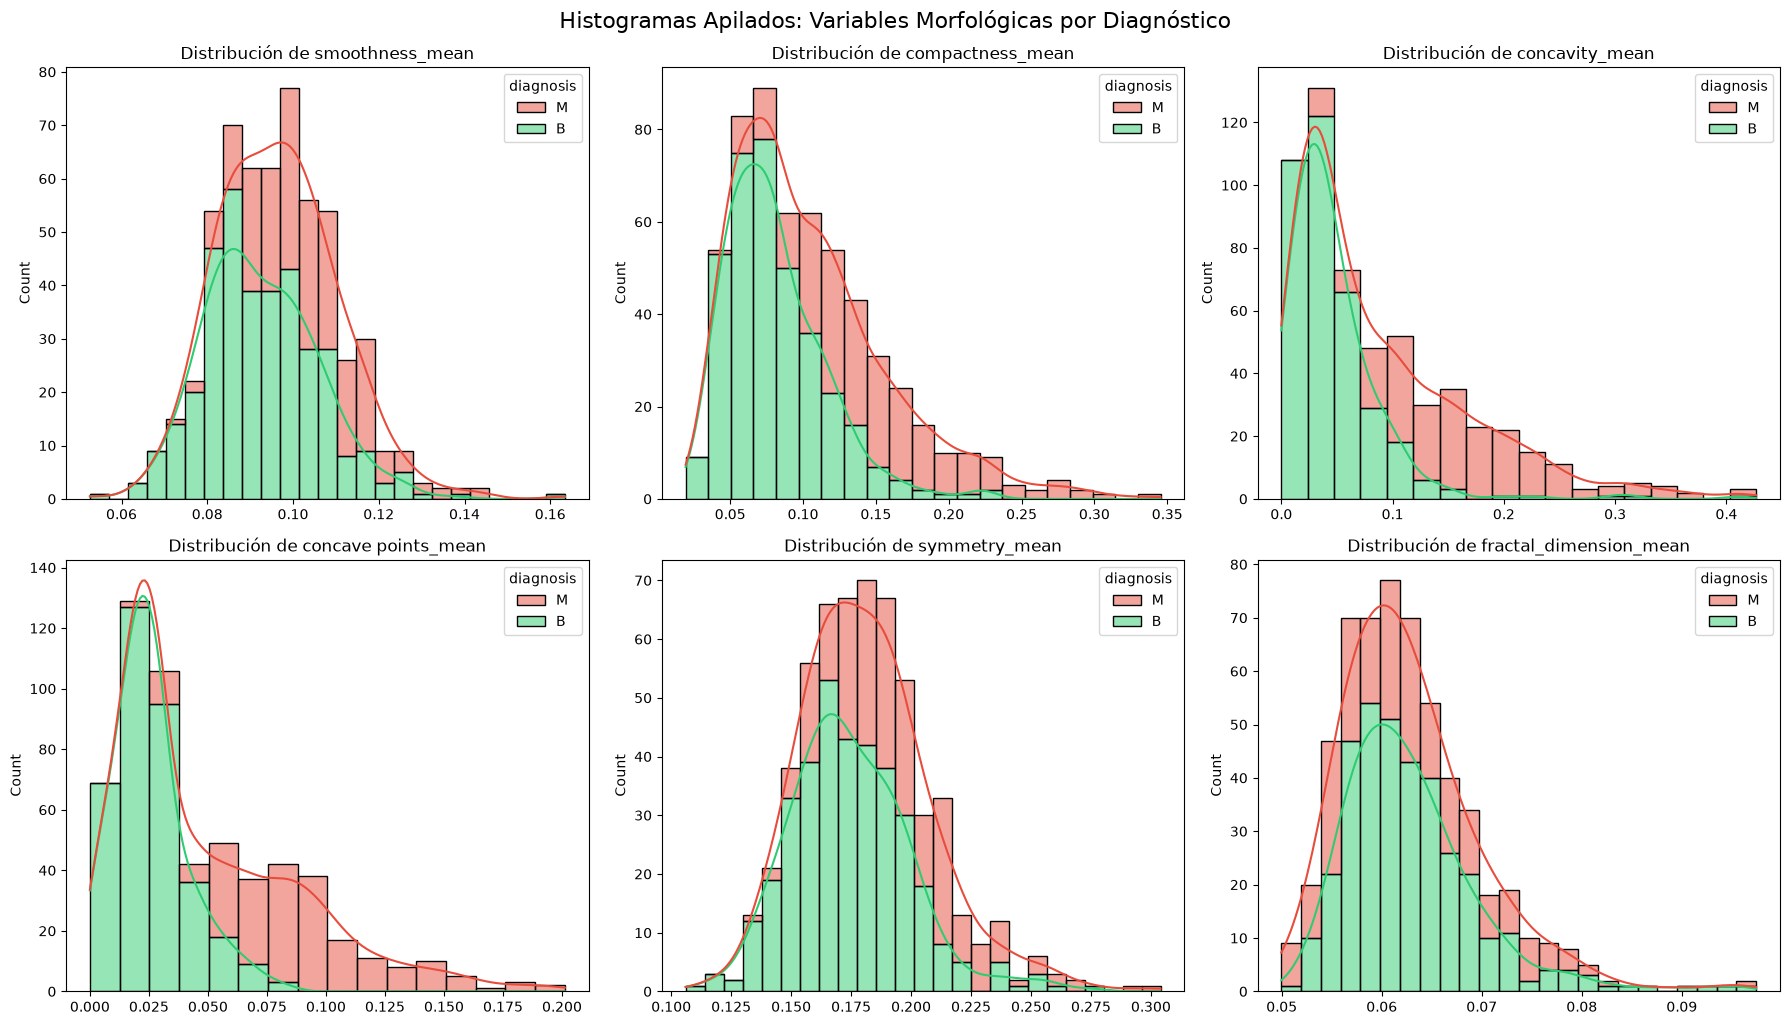

In [7]:
morfo_mapping = {
    'mean smoothness': 'smoothness_mean',
    'mean compactness': 'compactness_mean',
    'mean concavity': 'concavity_mean',
    'mean concave points': 'concave points_mean',
    'mean symmetry': 'symmetry_mean',
    'mean fractal dimension': 'fractal_dimension_mean'
}

morfo_vars = list(morfo_mapping.values())
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()


for i, var in enumerate(morfo_vars):
    sns.histplot(
        data=cancer_df,
        x=var,
        hue='diagnosis',
        multiple="stack",
        palette={'M': '#e74c3c', 'B': '#2ecc71'},
        ax=axes[i],
        kde=True # Añadimos la curva para ver mejor la tendencia
    )
    axes[i].set_title(f'Distribución de {var}', fontsize=12)
    axes[i].set_xlabel('')

plt.tight_layout()
plt.suptitle('Histogramas Apilados: Variables Morfológicas por Diagnóstico', y=1.02, fontsize=16)
plt.show()

concave points_mean y concavity_mean están muy desplazadas a la derecha respecto a las verdes (B). Esto significa que estas dos variables son altamente predictivas por sí solas.

Vamos a calcular y visualizar la distribución porcentual de la variable diagnosis usando un gráfico de barras, mostrando el porcentaje encima de cada barra. Esto es de suma importancia ya que determina cómo "aprende" el modelo y qué tan confiables serán sus predicciones. Por ejemplo si tuvieramos en 95% de tumores benignos el algoritmo simplemente podria poblar la variable resultante siempre como benigno y tendra un 95 % de precision ignorando la clase que nos interesa descubrir.



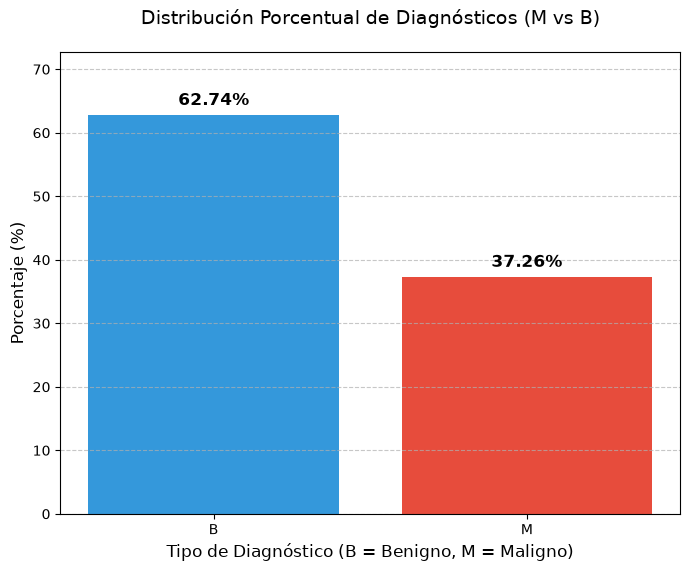

In [8]:
dist_pct = cancer_df['diagnosis'].value_counts(normalize=True) * 100
plt.figure(figsize=(8, 6))
bars = plt.bar(dist_pct.index, dist_pct.values, color=['#3498db', '#e74c3c'])
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1,
             f'{height:.2f}%',
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.title('Distribución Porcentual de Diagnósticos (M vs B)', fontsize=14, pad=20)
plt.xlabel('Tipo de Diagnóstico (B = Benigno, M = Maligno)', fontsize=12)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.ylim(0, max(dist_pct.values) + 10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

Ademas la distribución define qué métricas debemos usar para evaluar el éxito. En un dataset balanceado (como el este, 60/40), la Accuracy es una métrica aceptable. En un dataset desbalanceado, la Accuracy es engañosa. En su lugar, debemos mirar el Recall (Sensibilidad) o el F1-Score.

La alta correlación entre las variables del conjunto _mean y _worst es inevitable, ya que las columnas _worst representan esencialmente los valores máximos de las mismas características medidas en _mean. Por lo que vamos a eliminar las variable _worst


In [9]:
cols_to_drop = [col for col in cancer_df.columns if col.endswith('_worst')]

cancer_df.drop(columns=cols_to_drop, inplace=True)

Vamos a generar un mapa de calor para observar la relacion entre variables.

<Axes: >

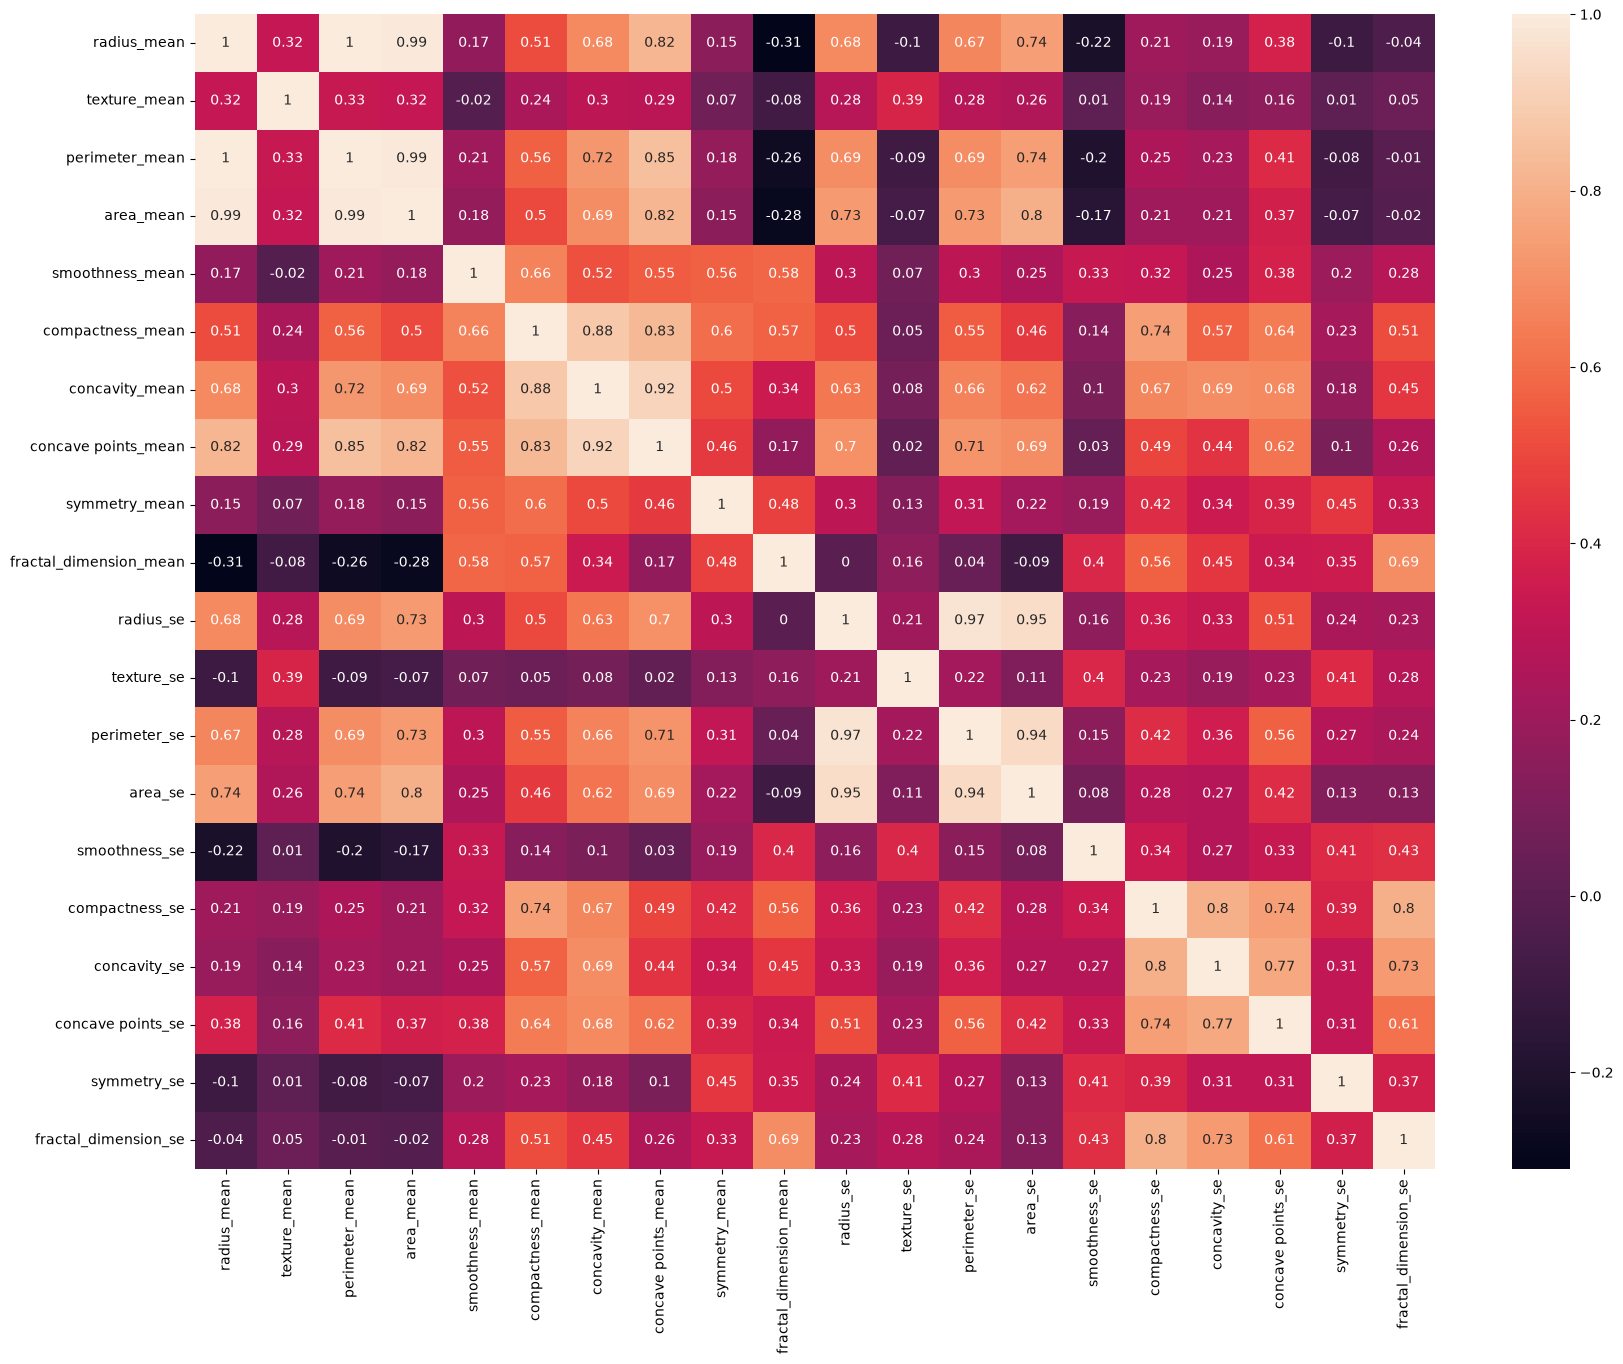

In [10]:
Tcorrelation = cancer_df.corr(method='pearson',numeric_only=True)
plt.rcParams['figure.figsize'] = (20, 15)
sns.heatmap(round(Tcorrelation,2), annot=True)

In [11]:
mask = np.triu(np.ones(Tcorrelation.shape), k=1).astype(bool)
df_pairs = Tcorrelation.where(mask).stack().reset_index()
df_pairs.columns = ['Variable 1', 'Variable 2', 'Correlacion']
high_corr = df_pairs[df_pairs['Correlacion'] > 0.9].sort_values(by='Correlacion', ascending=False)
high_corr

,Variable 1,Variable 2,Correlacion
2,radius_mean,perimeter_mean,0.997855
3,radius_mean,area_mean,0.987357
43,perimeter_mean,area_mean,0.986507
212,radius_se,perimeter_se,0.972794
213,radius_se,area_se,0.951830
253,perimeter_se,area_se,0.937655
127,concavity_mean,concave points_mean,0.921391


Como se puede observar existen relaciones lineales entre radius, perimeter y area. Vamos a mantener el area ya que al ser un elemento cuadratico es mas sensible al cambio de tamaño que es determinante para predecir si un tumor es benigno a maligno y vamos a eliminar radius y perimeter.

In [12]:
cancer_df.drop(columns=['perimeter_mean', 'radius_mean'], inplace=True)


Al existir una correlacion entre concavity_mean y concave points_mean voy a eliminar concave points_mean. Aunque es un predictor muy fuerte, la concavidad suele ser una medida más rica y descriptiva de la morfología irregular del cáncer. Además, al eliminar los "puntos cóncavos", se libera al modelo de una variable que es casi un espejo de la otra.

In [13]:
cancer_df.drop(columns=['concave points_mean'], inplace=True)

Ahora que entendemos nuestros datos, validamos valores faltantes y duplicados, eliminamos variables que no nos aportan informacion valiosa o esa informacion esta en otras variables, podemos empezar a entrenar modelos.

Vamos a separar las variables predictoras X de la variable de salida codificando diagnosis como 0 (Benigno) y 1 (Maligno).

Vamos a generar nuestros datos de entrenamiento y pruba.

Como primer modelo crearemos un dummy en donde se asigne aleatoriamente la prediccion.

In [14]:
X = cancer_df.drop('diagnosis', axis=1)
y = cancer_df['diagnosis']
y = cancer_df['diagnosis'].map({'M': 1, 'B': 0})

Vamos a crear una funcion que evalue nuestro modelo y agrege las metricas a MLflow

In [20]:
def evaluate_model(y_true, y_pred, model_name, results_df):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", recall)
    mlflow.log_metric("Recall", accuracy)
    print(f"--- Evaluación: {model_name} ---")
    print(f"Exactitud:  {accuracy:.2%}")
    print(f"Precisión: {precision:.2%}")
    print(f"Sensibilidad (Recall): {recall:.2%}\n")
    print("Matriz de Confusión:")
    print(confusion_matrix(y_true, y_pred))

    new_record = {
        'Modelo': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall
    }

    results_df = pd.concat([results_df, pd.DataFrame([new_record])], ignore_index=True)

    return results_df

In [16]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=1)

In [21]:
mlflow.set_tracking_uri(uri="http://127.0.0.1:5000")
mlflow.set_experiment("cancer_prediction")

2026/10/03 15:32:43 INFO mlflow.tracking.fluent: Experiment with name 'cancer_prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1791063163094, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791063163094, lifecycle_stage='active', name='cancer_prediction', tags={}, trace_location=None, workspace='default'>

In [23]:
params = {
    "strategy": "stratified",
    "random_state": 7
}

modeloDummy = DummyClassifier(strategy='stratified', random_state=7)  # Inicializamos el modelo Dummy con el crierio de
                                                           # predecir aleatorio
with mlflow.start_run():
    modeloDummy.fit(Xtrain, ytrain)       # entrenamos con los conjuntos de entrenamiento
    ypred = modeloDummy.predict(Xtest)
    mlflow.log_params(params)
    Correlation_Clean = pd.DataFrame(columns=['Modelo', 'Accuracy', 'Precision', 'Recall']) # Aunque sabemos que la metrica de interes es Accuracy vamos a logear las demas tambien
    evaluate_model(ytest, ypred, "Dummy", Correlation_Clean)
    signature = infer_signature(Xtrain, modeloDummy.predict(Xtest))
    model_info = mlflow.sklearn.log_model(
        sk_model=modeloDummy,
        name = "dummy_model",
        signature=signature,
        input_example = Xtrain,
        registered_model_name = "Dummy model for cancer prediction",
    )

    mlflow.set_logged_model_tags(
        model_info.model_id,
        {"training info": "Model inicial (Dummy) para predecir si un tumor es cancerigeno"}
    )

--- Evaluación: Dummy ---
Exactitud:  54.39%
Precisión: 38.10%
Sensibilidad (Recall): 38.10%

Matriz de Confusión:
[[46 26]
 [26 16]]


Successfully registered model 'Dummy model for cancer prediction'.
2026/10/03 15:38:36 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Dummy model for cancer prediction, version 1


🏃 View run smiling-cod-182 at: http://127.0.0.1:5000/#/experiments/1/runs/1a8a8884d65845bd90d5a4838365bc94
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Created version '1' of model 'Dummy model for cancer prediction'.


In [24]:
params = {
    "max_iter": 10000
}

with mlflow.start_run():
    lr_model = LogisticRegression(max_iter=10000)
    mlflow.log_params(params)
    lr_model.fit(Xtrain, ytrain)
    y_lr_pred = lr_model.predict(Xtest)
    evaluate_model(ytest, y_lr_pred, "lr_model", Correlation_Clean)
    signature = infer_signature(Xtrain, lr_model.predict(Xtest))
    model_info = mlflow.sklearn.log_model(
            sk_model=lr_model,
            name = "linear_regression_model",
            signature=signature,
            input_example = Xtrain,
            registered_model_name = "Linear regression model for cancer prediction",
        )
    
    mlflow.set_logged_model_tags(
        model_info.model_id,
        {"training info": "Regresion linear para predecir si un tumor es cancerigeno"}
    )

--- Evaluación: lr_model ---
Exactitud:  88.60%
Precisión: 91.43%
Sensibilidad (Recall): 76.19%

Matriz de Confusión:
[[69  3]
 [10 32]]


Successfully registered model 'Linear regression model for cancer prediction'.
2026/10/03 15:50:15 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: Linear regression model for cancer prediction, version 1


🏃 View run upset-snake-234 at: http://127.0.0.1:5000/#/experiments/1/runs/3276ce88e83544d0bf9c1981a36c2971
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


Created version '1' of model 'Linear regression model for cancer prediction'.


**Parte 7:**

Yo agregaria tambien las transformaciones que se estan haciendo sobre los datos. Aun no vemos cierta informacion pero para este caso podria ayuar mucho implementar un pipeline en donde escalemos los datos como por ejemplo con MinMax Scaler, apliquemos una reduccion  de caracterizticas PCA y realicemos la regresion logistica y seria bueno que quedara registro de las transformaciones de pipeline y no solo los parametros y resultados del modelo.

Como desarrollador de software dejar un regitro de ejecuciones con ciertos resultados es una buena practica, y aunque actualmente no estoy involucrado en el proceso de creacion de IA me es muy util para poder definir un path de carrera en esta nueva era donde las posibilidades se estan abriendo a perfiles como Data scients, Devops, analista de datos u otros que podamos ir descubriendo en el curso.